In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

In [3]:
df = pd.read_csv("creditcard.csv")

In [4]:
print(df.head())
print("Shape:", df.shape)

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [5]:
normal = df[df["Class"] == 0]
fraud = df[df["Class"] == 1]

print("Normal Transactions:", len(normal))
print("Fraud Transactions:", len(fraud))

Normal Transactions: 278097
Fraud Transactions: 487


In [6]:
X_normal = normal.drop("Class", axis=1)
X_fraud = fraud.drop("Class", axis=1)

X_train, X_test_normal = train_test_split(
    X_normal,
    test_size=0.2,
    random_state=42
)

# Test data = normal + fraud
X_test = pd.concat([X_test_normal, X_fraud])

y_test = np.concatenate([
    np.zeros(len(X_test_normal)),
    np.ones(len(X_fraud))
])

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (222477, 30)
Testing Data: (56107, 30)


In [7]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Data normalized successfully")

Data normalized successfully


In [8]:
input_dim = X_train.shape[1]

input_layer = Input(shape=(input_dim,))

# Encoder
encoded = Dense(64, activation="relu")(input_layer)
encoded = Dense(32, activation="relu")(encoded)
latent = Dense(16, activation="relu")(encoded)

In [9]:
decoded = Dense(32, activation="relu")(latent)
decoded = Dense(64, activation="relu")(decoded)

output_layer = Dense(input_dim, activation="linear")(decoded)

autoencoder = Model(input_layer, output_layer)

In [10]:
autoencoder.compile(
    optimizer="adam",
    loss="mse"
)
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 30)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           1,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 32)                  │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 30)                  │           1,950 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 9,198 (35.93 KB)

 Trainable params: 9,198 (35.93 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
history = autoencoder.fit(
    X_train,
    X_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
5562/5562 ━━━━━━━━━━━━━━━━━━━━ 28s 4ms/step - loss: 0.2801 - val_loss: 0.1291
Epoch 2/10
5562/5562 ━━━━━━━━━━━━━━━━━━━━ 29s 5ms/step - loss: 0.1145 - val_loss: 0.1010
Epoch 3/10
5562/5562 ━━━━━━━━━━━━━━━━━━━━ 18s 3ms/step - loss: 0.0877 - val_loss: 0.0761
Epoch 4/10
5562/5562 ━━━━━━━━━━━━━━━━━━━━ 16s 3ms/step - loss: 0.0742 - val_loss: 0.0759
Epoch 5/10
5562/5562 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step - loss: 0.0646 - val_loss: 0.0560
Epoch 6/10
5562/5562 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step - loss: 0.0605 - val_loss: 0.0536
Epoch 7/10
5562/5562 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step - loss: 0.0572 - val_loss: 0.0486
Epoch 8/10
5562/5562 ━━━━━━━━━━━━━━━━━━━━ 24s 4ms/step - loss: 0.0537 - val_loss: 0.0428
Epoch 9/10
5562/5562 ━━━━━━━━━━━━━━━━━━━━ 23s 4ms/step - loss: 0.0505 - val_loss: 0.0731
Epoch 10/10
5562/5562 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step - loss: 0.0496 - val_loss: 0.0499


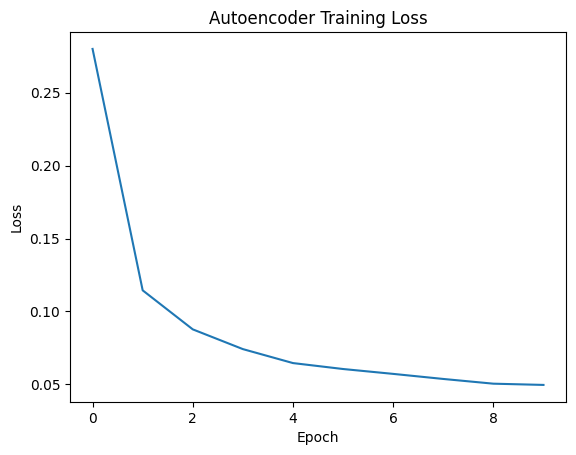

In [12]:
# Training Loss

plt.plot(history.history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Autoencoder Training Loss")
plt.show()

In [13]:
prediction = autoencoder.predict(X_test)

# Calculate reconstruction error
error = np.mean((X_test - prediction) ** 2, axis=1)

print("First 10 Reconstruction Errors:")
print(error[:10])

1754/1754 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step
First 10 Reconstruction Errors:
[0.00925531 0.1565747  0.09771767 0.00814382 0.13171803 0.19062802
 0.00777739 0.01408336 0.0117675  0.01149422]


In [14]:
threshold = np.percentile(error, 95)

print("Threshold:", threshold)

# Error greater than threshold = Fraud
y_pred = (error > threshold).astype(int)

print("\nDetected Fraud:", sum(y_pred))
print("Detected Normal:", sum(y_pred == 0))

Threshold: 0.20592997211883168

Detected Fraud: 2806
Detected Normal: 53301


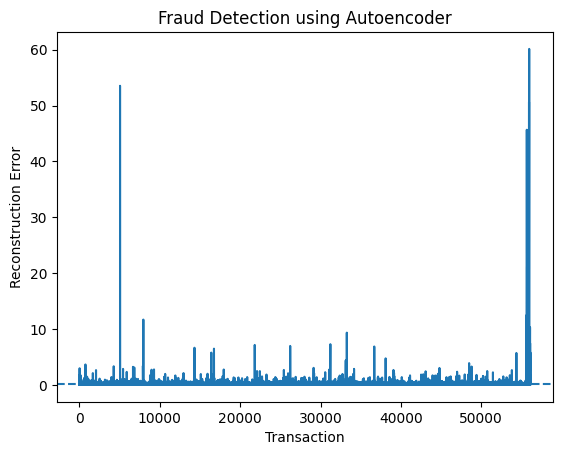

In [16]:
# (h) Reconstruction Error Graph

plt.plot(error)
plt.axhline(threshold, linestyle="--")

plt.xlabel("Transaction")
plt.ylabel("Reconstruction Error")
plt.title("Fraud Detection using Autoencoder")

plt.show()

In [17]:
# (h) Evaluation

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9559947956582957


In [19]:
# Create result table

result = pd.DataFrame({
    "Actual": y_test.astype(int),
    "Reconstruction_Error": error,
    "Predicted": y_pred
})

print(result.head(10))

   Actual  Reconstruction_Error  Predicted
0       0              0.009255          0
1       0              0.156575          0
2       0              0.097718          0
3       0              0.008144          0
4       0              0.131718          0
5       0              0.190628          0
6       0              0.007777          0
7       0              0.014083          0
8       0              0.011768          0
9       0              0.011494          0


In [20]:
# Display detected fraudulent transactions

fraud_detected = result[result["Predicted"] == 1]

print("Detected Fraudulent Transactions:")
print(fraud_detected.head(10))

Detected Fraudulent Transactions:
     Actual  Reconstruction_Error  Predicted
14        0              0.259724          1
18        0              1.741771          1
20        0              2.986078          1
42        0              0.591907          1
46        0              0.332649          1
68        0              0.280478          1
93        0              0.219210          1
99        0              0.341391          1
125       0              1.764612          1
160       0              0.279071          1
